Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Correlação Demanda: -0.8858
Correlação Oferta:  0.7854

Teste Pearson Demanda -> r = -0.8858, p-valor = 0.0000e+00
Teste Pearson Oferta  -> r = 0.7854, p-valor = 0.0000e+00

Matriz de Correlação:
           log_p    log_qd    log_qs
log_p   1.000000 -0.885826  0.785389
log_qd -0.885826  1.000000 -0.692896
log_qs  0.785389 -0.692896  1.000000


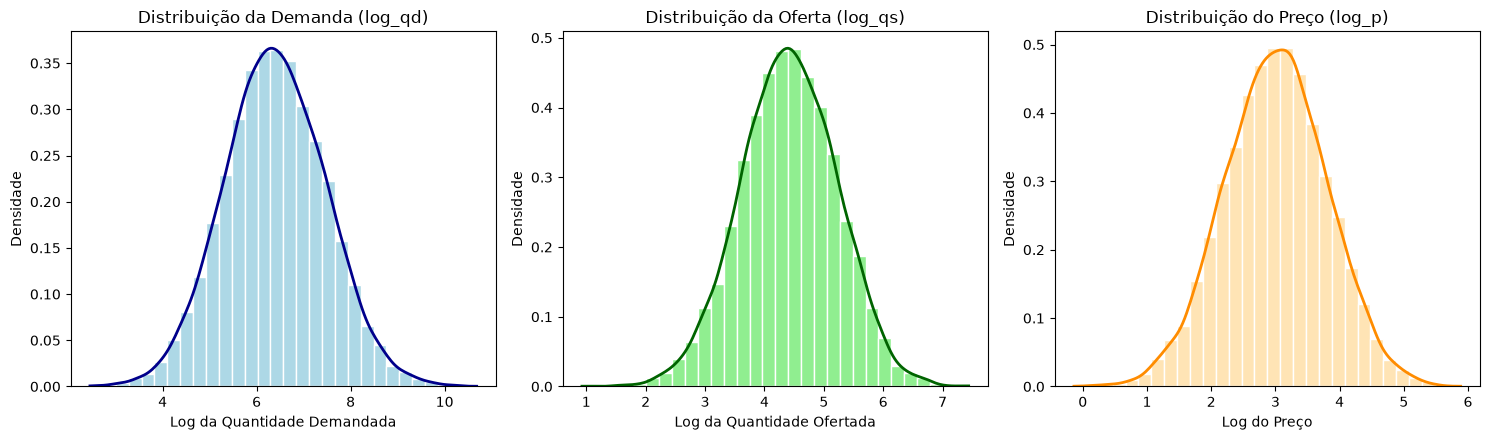

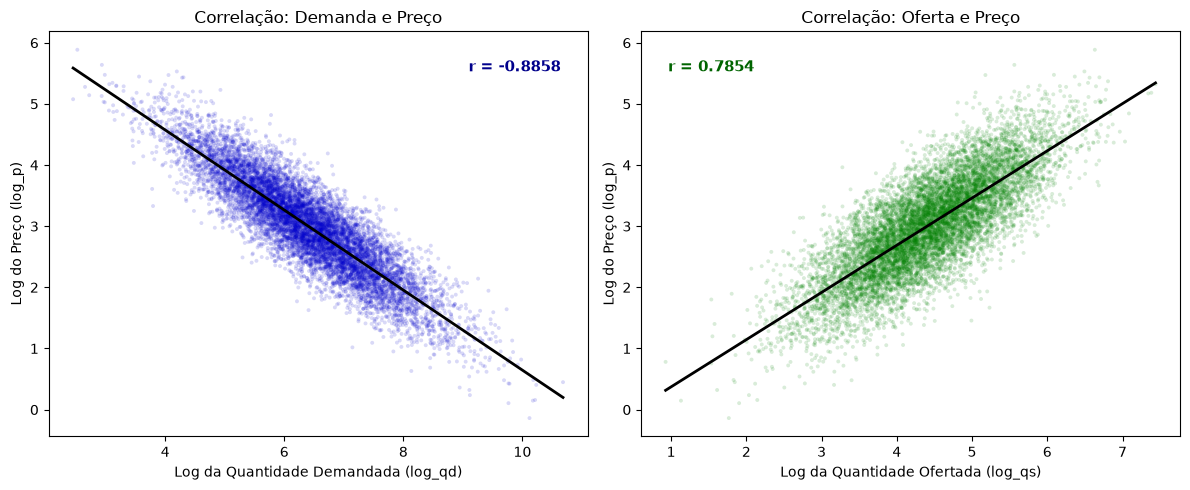

                            OLS Regression Results                            
Dep. Variable:                 log_qd   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.785
Method:                 Least Squares   F-statistic:                 3.644e+04
Date:                Sat, 14 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:30:25   Log-Likelihood:                -7268.7
No. Observations:               10000   AIC:                         1.454e+04
Df Residuals:                    9998   BIC:                         1.456e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.9972      0.020    511.846      0.0

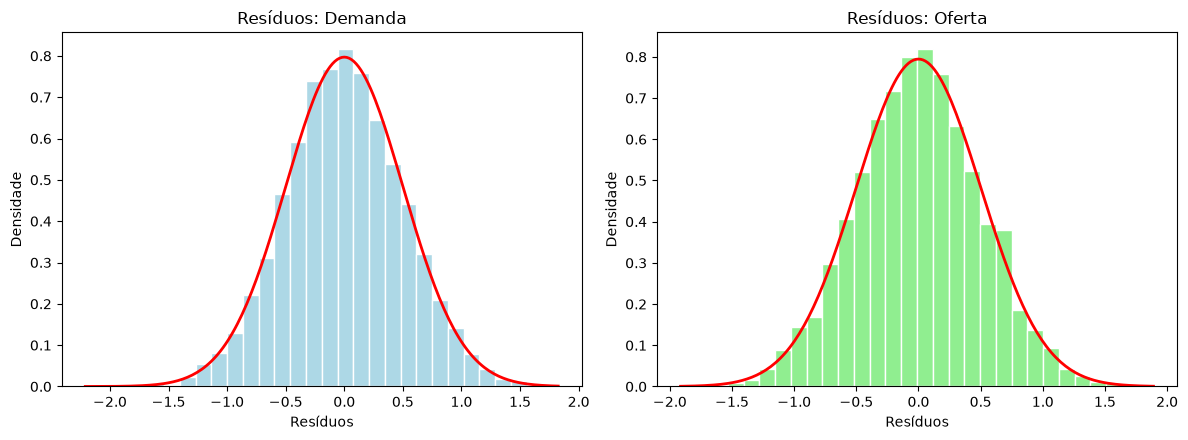

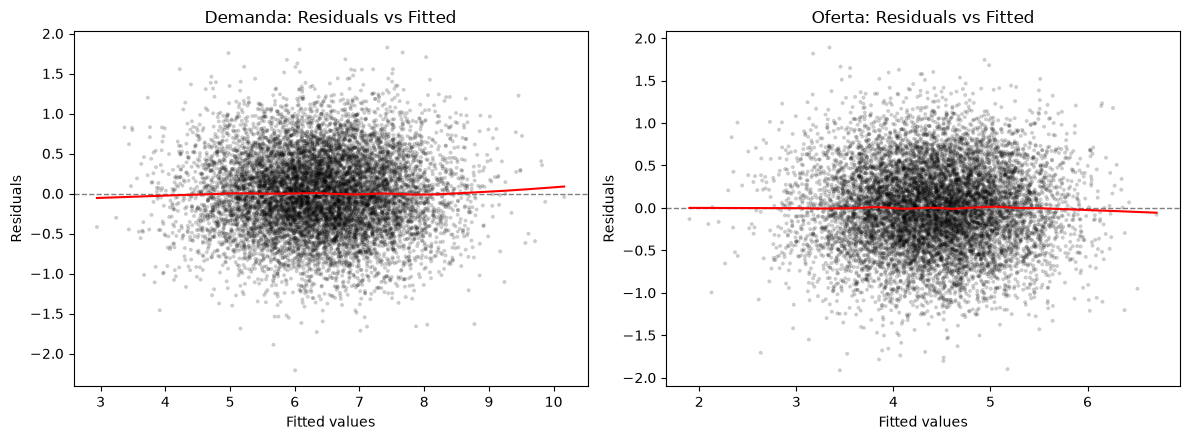

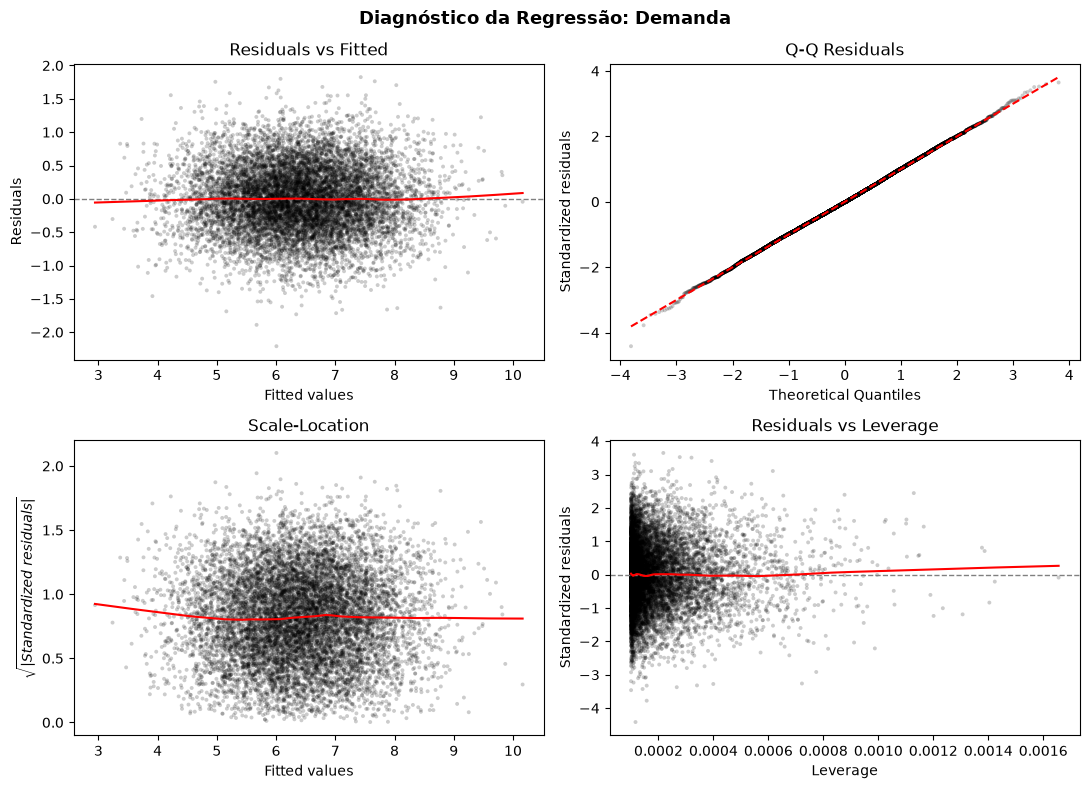

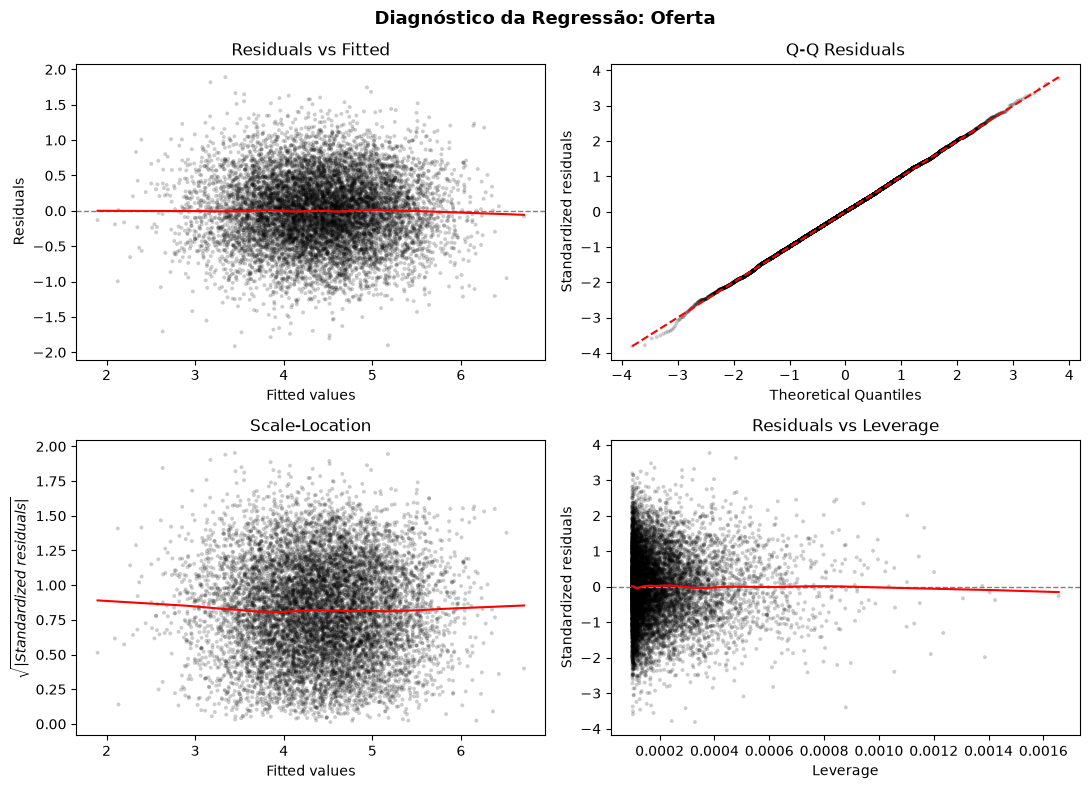

In [2]:
# %%
# Aula 01 - Revisão: regressão linear simples e principais conceitos
#
# Prof. Elson Rodrigo de Souza Santos
# E-mail: elson.rodrigo@ufabc.edu.br ou elson129@gmail.com
#
# Universidade Federal do ABC (UFABC)
# Bacharel em Ciências Econômicas
# Econometria I - 2026.3
# Disciplina: Econometria I - 2026.3
# Universidade Federal do ABC (UFABC)
#
###
# Descrição:
# O script é o material de suporte para a aula 01 de econometria. Contém a simulação
# de dados para oferta e demanda. Em seguida, apresentação da correlação, tabela 
# de resultados e testes.
#
###
# Pacotes

%pip install numpy pandas matplotlib scipy statsmodels ipykernel

# Importação das bibliotecas necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# %%
# 1. Simulação de dados
#
# Simulamos 10 mil observações para oferta e demanda, considerando a quantidade
# e preços.

# Definir semente aleatória e tamanho da amostra
rng = np.random.default_rng(123)
n = 10000

# Simulação do preço em logaritmo natural
log_p = rng.normal(loc=3, scale=0.8, size=n)

# Simulação dos erros aleatórios (média zero e variância constante)
u_d = rng.normal(loc=0, scale=0.5, size=n)
u_s = rng.normal(loc=0, scale=0.5, size=n)

# Relações populacionais log-lineares
# Demanda: intercepto = 10, elasticidade-preço = -1.2
log_qd = 10 - 1.2 * log_p + u_d

# Oferta: intercepto = 2, elasticidade-preço = 0.8
log_qs = 2 + 0.8 * log_p + u_s

# Organização da base em corte transversal (DataFrame)
dados = pd.DataFrame({
    "id": np.arange(1, n + 1),
    "log_p": log_p,
    "log_qd": log_qd,
    "log_qs": log_qs
})

dados.head()

# %%
# 2. Correlação

# Coeficiente de correlação de Pearson
cor_demanda = dados["log_p"].corr(dados["log_qd"])
cor_oferta = dados["log_p"].corr(dados["log_qs"])

print(f"Correlação Demanda: {cor_demanda:.4f}")
print(f"Correlação Oferta:  {cor_oferta:.4f}\n")

# Teste de hipótese para a correlação
r_d, p_val_d = stats.pearsonr(dados["log_p"], dados["log_qd"])
r_s, p_val_s = stats.pearsonr(dados["log_p"], dados["log_qs"])

print(f"Teste Pearson Demanda -> r = {r_d:.4f}, p-valor = {p_val_d:.4e}")
print(f"Teste Pearson Oferta  -> r = {r_s:.4f}, p-valor = {p_val_s:.4e}\n")

# Matriz de correlação entre as três variáveis
print("Matriz de Correlação:")
print(dados[["log_p", "log_qd", "log_qs"]].corr())

# %%
# Distribuições marginais (1 linha e 3 colunas)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Distribuição da quantidade demandada (log_qd)
axes[0].hist(dados["log_qd"], bins=30, density=True, color="lightblue", edgecolor="white")
kde_qd = stats.gaussian_kde(dados["log_qd"])
x_qd = np.linspace(dados["log_qd"].min(), dados["log_qd"].max(), 200)
axes[0].plot(x_qd, kde_qd(x_qd), color="darkblue", linewidth=2)
axes[0].set_title("Distribuição da Demanda (log_qd)")
axes[0].set_xlabel("Log da Quantidade Demandada")
axes[0].set_ylabel("Densidade")

# Distribuição da quantidade ofertada (log_qs)
axes[1].hist(dados["log_qs"], bins=30, density=True, color="lightgreen", edgecolor="white")
kde_qs = stats.gaussian_kde(dados["log_qs"])
x_qs = np.linspace(dados["log_qs"].min(), dados["log_qs"].max(), 200)
axes[1].plot(x_qs, kde_qs(x_qs), color="darkgreen", linewidth=2)
axes[1].set_title("Distribuição da Oferta (log_qs)")
axes[1].set_xlabel("Log da Quantidade Ofertada")
axes[1].set_ylabel("Densidade")

# Distribuição do preço (log_p)
axes[2].hist(dados["log_p"], bins=30, density=True, color="moccasin", edgecolor="white")
kde_p = stats.gaussian_kde(dados["log_p"])
x_p = np.linspace(dados["log_p"].min(), dados["log_p"].max(), 200)
axes[2].plot(x_p, kde_p(x_p), color="darkorange", linewidth=2)
axes[2].set_title("Distribuição do Preço (log_p)")
axes[2].set_xlabel("Log do Preço")
axes[2].set_ylabel("Densidade")

plt.tight_layout()
plt.show()

# %%
# Gráfico de correlação preço e quantidade (preço no eixo vertical)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Correlação: Demanda vs. Preço
r_demanda = round(dados["log_qd"].corr(dados["log_p"]), 4)
axes[0].scatter(dados["log_qd"], dados["log_p"], s=8, color=(0, 0, 0.8, 0.15), edgecolors="none")
b1_d, b0_d = np.polyfit(dados["log_qd"], dados["log_p"], 1)
x_grid_d = np.linspace(dados["log_qd"].min(), dados["log_qd"].max(), 100)
axes[0].plot(x_grid_d, b0_d + b1_d * x_grid_d, color="black", linewidth=2)
axes[0].set_title("Correlação: Demanda e Preço")
axes[0].set_xlabel("Log da Quantidade Demandada (log_qd)")
axes[0].set_ylabel("Log do Preço (log_p)")
axes[0].text(0.95, 0.93, f"r = {r_demanda}", transform=axes[0].transAxes,
             ha="right", va="top", color="darkblue", fontweight="bold", fontsize=11)

# Correlação: Oferta vs. Preço
r_oferta = round(dados["log_qs"].corr(dados["log_p"]), 4)
axes[1].scatter(dados["log_qs"], dados["log_p"], s=8, color=(0, 0.5, 0, 0.15), edgecolors="none")
b1_s, b0_s = np.polyfit(dados["log_qs"], dados["log_p"], 1)
x_grid_s = np.linspace(dados["log_qs"].min(), dados["log_qs"].max(), 100)
axes[1].plot(x_grid_s, b0_s + b1_s * x_grid_s, color="black", linewidth=2)
axes[1].set_title("Correlação: Oferta e Preço")
axes[1].set_xlabel("Log da Quantidade Ofertada (log_qs)")
axes[1].set_ylabel("Log do Preço (log_p)")
axes[1].text(0.05, 0.93, f"r = {r_oferta}", transform=axes[1].transAxes,
             ha="left", va="top", color="darkgreen", fontweight="bold", fontsize=11)

plt.tight_layout()
plt.show()

# %%
# 3. Regressão linear simples

# Modelos OLS (sintaxe de fórmula equivalente ao lm() do R)
modelo_demanda = smf.ols("log_qd ~ log_p", data=dados).fit()
modelo_oferta = smf.ols("log_qs ~ log_p", data=dados).fit()

# Resultados
print(modelo_demanda.summary())
print("\n" + "=" * 80 + "\n")
print(modelo_oferta.summary())

# %%
# 4. Normalidade dos erros

# Extrair os resíduos
res_d = modelo_demanda.resid
res_o = modelo_oferta.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Distribuição dos resíduos da Demanda
axes[0].hist(res_d, bins=30, density=True, color="lightblue", edgecolor="white")
x_rd = np.linspace(res_d.min(), res_d.max(), 200)
axes[0].plot(x_rd, stats.norm.pdf(x_rd, loc=res_d.mean(), scale=res_d.std()), color="red", linewidth=2)
axes[0].set_title("Resíduos: Demanda")
axes[0].set_xlabel("Resíduos")
axes[0].set_ylabel("Densidade")

# Distribuição dos resíduos da Oferta
axes[1].hist(res_o, bins=30, density=True, color="lightgreen", edgecolor="white")
x_ro = np.linspace(res_o.min(), res_o.max(), 200)
axes[1].plot(x_ro, stats.norm.pdf(x_ro, loc=res_o.mean(), scale=res_o.std()), color="red", linewidth=2)
axes[1].set_title("Resíduos: Oferta")
axes[1].set_xlabel("Resíduos")
axes[1].set_ylabel("Densidade")

plt.tight_layout()
plt.show()

# %%
# Gráfico direto de Homoscedasticidade (Resíduos vs. Valores Ajustados)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Demanda
axes[0].scatter(modelo_demanda.fittedvalues, res_d, s=8, color=(0, 0, 0, 0.2), edgecolors="none")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
lowess_d = sm.nonparametric.lowess(res_d, modelo_demanda.fittedvalues, frac=0.3)
axes[0].plot(lowess_d[:, 0], lowess_d[:, 1], color="red", linewidth=1.5)
axes[0].set_title("Demanda: Residuals vs Fitted")
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")

# Oferta
axes[1].scatter(modelo_oferta.fittedvalues, res_o, s=8, color=(0, 0, 0, 0.2), edgecolors="none")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
lowess_s = sm.nonparametric.lowess(res_o, modelo_oferta.fittedvalues, frac=0.3)
axes[1].plot(lowess_s[:, 0], lowess_s[:, 1], color="red", linewidth=1.5)
axes[1].set_title("Oferta: Residuals vs Fitted")
axes[1].set_xlabel("Fitted values")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.show()

# %%
# Gráficos diagnósticos completos (equivalente ao plot(modelo) 2x2 do R)
def painel_diagnostico(modelo, titulo_geral):
    infl = modelo.get_influence()
    resid = modelo.resid
    fitted = modelo.fittedvalues
    std_resid = infl.resid_studentized_internal
    leverage = infl.hat_matrix_diag
    sqrt_std_resid = np.sqrt(np.abs(std_resid))

    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    fig.suptitle(titulo_geral, fontsize=13, fontweight="bold")

    # 1. Residuals vs Fitted
    axes[0, 0].scatter(fitted, resid, s=8, color=(0, 0, 0, 0.2), edgecolors="none")
    axes[0, 0].axhline(0, color="gray", linestyle="--", linewidth=1)
    lowess1 = sm.nonparametric.lowess(resid, fitted, frac=0.3)
    axes[0, 0].plot(lowess1[:, 0], lowess1[:, 1], color="red", linewidth=1.5)
    axes[0, 0].set_title("Residuals vs Fitted")
    axes[0, 0].set_xlabel("Fitted values")
    axes[0, 0].set_ylabel("Residuals")

    # 2. Q-Q Residuals
    (osm, osr), (slope, intercept, _) = stats.probplot(std_resid, dist="norm")
    axes[0, 1].scatter(osm, osr, s=8, color=(0, 0, 0, 0.2), edgecolors="none")
    axes[0, 1].plot(osm, slope * osm + intercept, color="red", linestyle="--", linewidth=1.5)
    axes[0, 1].set_title("Q-Q Residuals")
    axes[0, 1].set_xlabel("Theoretical Quantiles")
    axes[0, 1].set_ylabel("Standardized residuals")

    # 3. Scale-Location
    axes[1, 0].scatter(fitted, sqrt_std_resid, s=8, color=(0, 0, 0, 0.2), edgecolors="none")
    lowess3 = sm.nonparametric.lowess(sqrt_std_resid, fitted, frac=0.3)
    axes[1, 0].plot(lowess3[:, 0], lowess3[:, 1], color="red", linewidth=1.5)
    axes[1, 0].set_title("Scale-Location")
    axes[1, 0].set_xlabel("Fitted values")
    axes[1, 0].set_ylabel(r"$\sqrt{|Standardized\ residuals|}$")

    # 4. Residuals vs Leverage
    axes[1, 1].scatter(leverage, std_resid, s=8, color=(0, 0, 0, 0.2), edgecolors="none")
    axes[1, 1].axhline(0, color="gray", linestyle="--", linewidth=1)
    lowess4 = sm.nonparametric.lowess(std_resid, leverage, frac=0.3)
    axes[1, 1].plot(lowess4[:, 0], lowess4[:, 1], color="red", linewidth=1.5)
    axes[1, 1].set_title("Residuals vs Leverage")
    axes[1, 1].set_xlabel("Leverage")
    axes[1, 1].set_ylabel("Standardized residuals")

    plt.tight_layout()
    plt.show()

# Demanda
painel_diagnostico(modelo_demanda, "Diagnóstico da Regressão: Demanda")

# Oferta
painel_diagnostico(modelo_oferta, "Diagnóstico da Regressão: Oferta")

###
# FIM